In [40]:
import pandas as pd
from sqlalchemy import create_engine

In [41]:
host="localhost"
user="root"
password=""
database="games"

#Creating a connection to the db
connection = f"mysql+pymysql://{user}:{password}@{host}/{database}"

engine = create_engine(connection)

query = """SELECT p.player_name AS player_name, p.age AS player_age,g.game_name AS game_name, g.game_type AS game_type,s.score AS score,s.play_date AS play_date,t.tournament_name AS tournament_name,t.location AS tournament_location,t.event_date AS tournament_date FROM game_sessions s
INNER JOIN players p ON s.player_id = p.player_id
INNER JOIN allgames g ON s.game_id = g.game_id
INNER JOIN tournaments t ON s.tournament_id = t.tournament_id;"""

df = pd.read_sql_query(query, engine)
df



,player_name,player_age,game_name,game_type,score,play_date,tournament_name,tournament_location,tournament_date
0,Alice,22,Chess,Board,85,2024-01-11,New Year Cup,Miami,2024-01-15
1,Bob,25,Checkers,Board,78,2024-01-11,New Year Cup,Miami,2024-01-15
2,Charlie,30,Scrabble,Board,90,2024-01-12,New Year Cup,Miami,2024-01-15
3,Diana,28,Monopoly,Board,70,2024-01-13,New Year Cup,Miami,2024-01-15
4,Ethan,35,Dominoes,Board,88,2024-01-14,New Year Cup,Miami,2024-01-15
5,Fiona,20,Uno,Card,95,2024-01-15,New Year Cup,Miami,2024-01-15
6,George,40,Poker,Card,60,2024-01-16,January Open,Boston,2024-01-29
7,Hannah,27,Soccer,Outdoor,72,2024-01-17,January Open,Boston,2024-01-29
8,Ian,33,Basketball,Outdoor,99,2024-01-18,January Open,Boston,2024-01-29
9,Julia,24,Tennis,Outdoor,55,2024-01-19,January Open,Boston,2024-01-29


In [42]:
# finding the shape of our dafaframe
df.shape

(20, 9)

In [43]:
# check for some info in regards to the generated dataframe
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   player_name          20 non-null     str   
 1   player_age           20 non-null     int64 
 2   game_name            20 non-null     str   
 3   game_type            20 non-null     str   
 4   score                20 non-null     int64 
 5   play_date            20 non-null     object
 6   tournament_name      20 non-null     str   
 7   tournament_location  20 non-null     str   
 8   tournament_date      20 non-null     object
dtypes: int64(2), object(2), str(5)
memory usage: 1.5+ KB


In [44]:
# summary statistics for numeric columns
df.describe()

,player_age,score
count,20.000000,20.000000
mean,28.400000,78.500000
std,6.038473,13.044458
min,20.000000,55.000000
25%,24.000000,69.750000
50%,27.500000,79.000000
75%,33.000000,89.250000
max,40.000000,99.000000


In [45]:
# Exporting the entire dataframe into a csv
df.to_csv("games_data.csv", index=False)

In [46]:
# check missing and duplicate values.
print(df.isnull().sum())
print("Duplicate rows: ", df.duplicated().sum())

player_name            0
player_age             0
game_name              0
game_type              0
score                  0
play_date              0
tournament_name        0
tournament_location    0
tournament_date        0
dtype: int64
Duplicate rows:  0


In [52]:
df.groupby("player").size()

player
Alice      2
Bob        2
Charlie    2
Diana      2
Ethan      2
Fiona      2
George     2
Hannah     2
Ian        2
Julia      2
dtype: int64

In [55]:
df.columns

Index(['player_name', 'player_age', 'game_name', 'game_type', 'score',
       'play_date', 'tournament_name', 'tournament_location',
       'tournament_date', 'player'],
      dtype='str')

In [56]:
df.groupby("tournament_name").size()

tournament_name
January Open    14
New Year Cup     6
dtype: int64

Text(0, 0.5, 'Count')

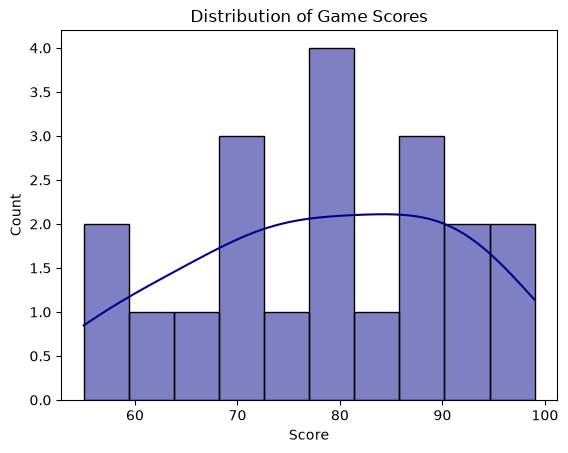

In [63]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(df["score"], bins=10, kde=True, color="darkblue")
plt.title("Distribution of Game Scores")
plt.xlabel("Score")
plt.ylabel("Count")


In [68]:
player_summary = df.groupby("player").agg(
    games=("game_name", "size"),
    avg_score=("score", "mean"),
    wins=("score", lambda x: (x > 70).sum()),   
    losses=("score", lambda x: (x <= 70).sum()) 
).round(2)

player_summary

,games,avg_score,wins,losses
player,,,,
Alice,2,82.5,2,0
Bob,2,85.0,2,0
Charlie,2,77.5,1,1
Diana,2,73.5,1,1
Ethan,2,88.5,2,0
Fiona,2,76.5,1,1
George,2,66.5,1,1
Hannah,2,76.5,2,0
Ian,2,96.5,2,0


In [70]:
player_summary = df.groupby("player").agg(
    games=("game_name", "size"),
    avg_score=("score", "mean"),
    min_score=("score", "min"),
    max_score=("score", "max"),
    tournaments_played=("tournament_name", "nunique")
).round(2)

player_summary

,games,avg_score,min_score,max_score,tournaments_played
player,,,,,
Alice,2,82.5,80,85,2
Bob,2,85.0,78,92,2
Charlie,2,77.5,65,90,2
Diana,2,73.5,70,77,2
Ethan,2,88.5,88,89,2
Fiona,2,76.5,58,95,2
George,2,66.5,60,73,1
Hannah,2,76.5,72,81,1
Ian,2,96.5,94,99,1


In [75]:
tournament_summary = df.groupby("tournament_name").agg(
    games=("game_name", "size"),
    avg_score=("score", "mean"),
    players=("player", "nunique")
).round(2)

tournament_summary

,games,avg_score,players
tournament_name,,,
January Open,14,76.00,10
New Year Cup,6,84.33,6


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_17736\1134572157.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(y="player", data=df, palette="autumn")


(array([0.  , 0.25, 0.5 , 0.75, 1.  , 1.25, 1.5 , 1.75, 2.  , 2.25]),
 [Text(0.0, 0, '0.00'),
  Text(0.25, 0, '0.25'),
  Text(0.5, 0, '0.50'),
  Text(0.75, 0, '0.75'),
  Text(1.0, 0, '1.00'),
  Text(1.25, 0, '1.25'),
  Text(1.5, 0, '1.50'),
  Text(1.75, 0, '1.75'),
  Text(2.0, 0, '2.00'),
  Text(2.25, 0, '2.25')])

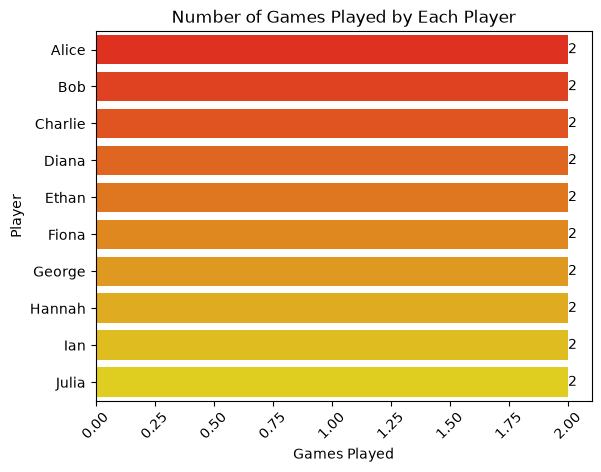

In [76]:
ax = sns.countplot(y="player", data=df, palette="autumn")

for container in ax.containers:
    ax.bar_label(container)

plt.title("Number of Games Played by Each Player")
plt.xlabel("Games Played")
plt.ylabel("Player")
plt.xticks(rotation=45)

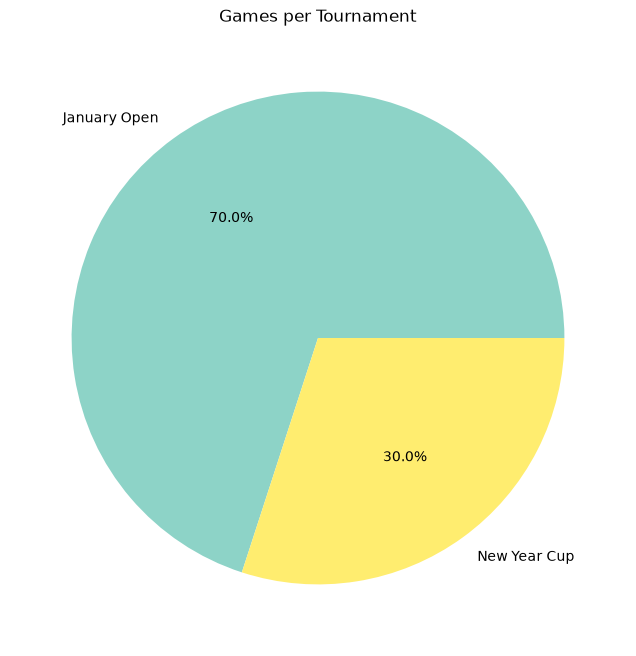

In [80]:
df["tournament_name"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(8, 8),
    colormap="Set3"
)

plt.title("Games per Tournament")
plt.ylabel("")   # removes the default label
plt.show()

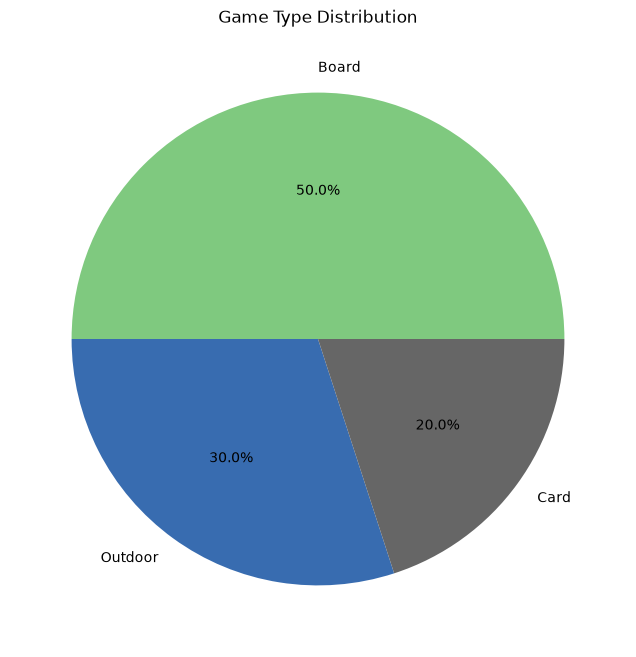

In [82]:
df["game_type"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(8, 8),
    colormap="Accent"
)

plt.title("Game Type Distribution")
plt.ylabel("")
plt.show()